In [2]:
import torch
from torchvision import datasets
from torch import nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2

In [5]:
from datasets import load_dataset
ds = load_dataset("timm/eurosat-rgb")   # DatasetDict: train / validation / test
train = ds["train"]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

C:\Users\wasio\.conda\envs\dml\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\wasio\.cache\huggingface\hub\datasets--timm--eurosat-rgb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\wasio\.conda\envs\dml\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` c

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 55.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.4MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.4MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

In [12]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 16200
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
})

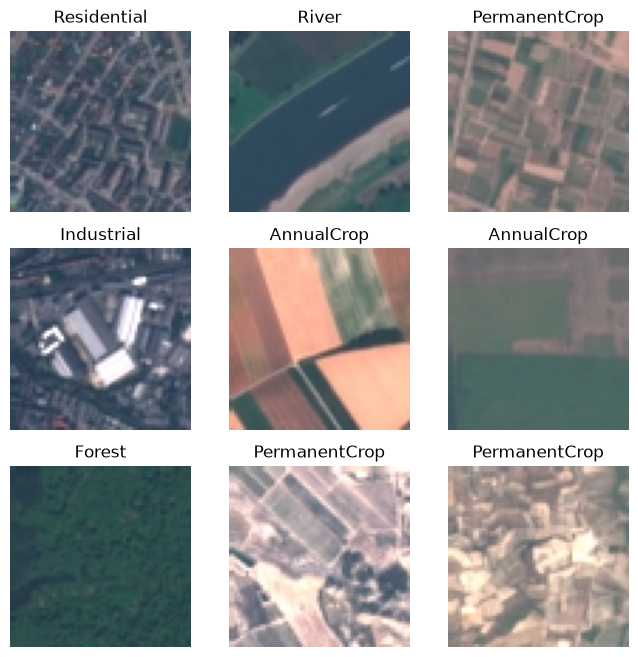

In [39]:
#visualization
import matplotlib.pyplot as plt
import random
labels_map = {
    0: "AnnualCrop",
    1: "Forest",
    2: "HerbaceousVegatation",
    3: "Highway",
    4: "Industrial",
    5: "Pasture",
    6: "PermanentCrop",
    7: "Residential",
    8: "River",
    9: "SeaLaket",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols*rows+1):
    sample_idx = random.randint(0,len(train)-1)    
    img, label = train['image'][sample_idx], train['label'][sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img)
plt.show()

In [56]:
from torch.utils.data import Dataset
class CustomDataset(Dataset):
    def __init__(self, Ds, transform):
        self.img_labels = Ds
        self.transform = transform
        
    def __len__(self):
        return len(self.img_labels)
    def __getitem__(self, idx):
        sample = self.img_labels[idx]
        image, label = sample['image'], sample['label']
        if self.transform:
            image = self.transform(image)
        return image, label

In [62]:
transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
train_set = CustomDataset(ds["train"], transform) 
val_set = CustomDataset(ds["validation"], transform)
test_set = CustomDataset(ds["test"], transform)

In [66]:
#loading the Dataset into the Dataloaders
train_dataloader = DataLoader(train_set, batch_size=32, shuffle=True)
val_dataloader = DataLoader(test_set, batch_size=32, shuffle=False)

Feature batch shape: torch.Size([32, 3, 64, 64])
Labels batch shape: torch.Size([32])


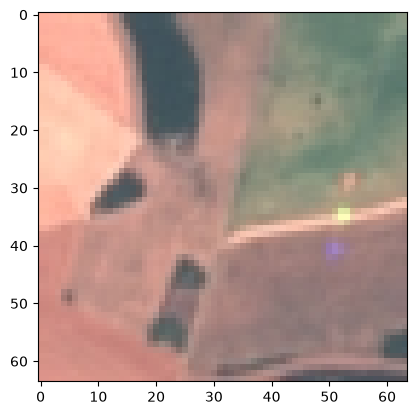

Label: 0


In [69]:
train_features, train_labels,  = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].permute(1, 2, 0)
label = train_labels[0]
plt.imshow(img)
plt.show()
print(f"Label: {label}")